# Malla de la derivación (tee) — media pieza + espejado

Variables y convenciones tomadas de `tee_bloques_v14.py`:

| Variable | Significado |
|---|---|
| `OD_1`, `OD_2` | OD del tubo directo / de la derivación (`OD_2 <= OD_1`) |
| `H_1` | de la entrada a la intersección (directo: x de `-H_1` a `+H_3`) |
| `H_2` | de la intersección a la salida lateral (boca de la derivación en `t = H_2` sobre su eje) |
| `H_3` | de la intersección a la salida final |
| `Alpha_2` | ángulo de la derivación [grados], en el plano xz |
| `N_directo` | divisiones de la boca del directo (múltiplo de 4) → define `dth` y `tam` |
| `R1`, `R2`, `alfa`, `eje_s`, `perp_s` | radios, ángulo en rad, eje de la derivación y transversal (plano xz) |
| `phi` | ángulo en la sección de la derivación: `y = R2 cosφ`, `v = R2 sinφ` (v sobre `perp_s`) |
| `N_s` | divisiones de la curva y de la derivación (par, para poder partirla por la mitad) |

**Estrategia:** la pieza es simétrica respecto del plano **zx** (y = 0) → se malla solo **y ≥ 0**
(φ ∈ [−π/2, π/2]), empezando por la derivación: curva de intersección → generatrices hasta la boca (t = `H_2`).
Sobre el **caño base** se agregan `capas_base` capas de elementos (3 por defecto) en el borde de la curva de intersección,
que comparten los nodos de la curva con la derivación. Finalmente el resto del caño directo se completa **desde las dos bocas hacia la corona** (bloques estructurados, sección 6b). Después se espejan nodos, elementos y valores nodales.

Cada celda define una sola función; ejecutá de arriba hacia abajo la primera vez y después modificá la que quieras.

## 1. Parámetros

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from collections import Counter

# Gráfico interactivo (se rota con el mouse): requiere ipympl  ->  uv add ipympl  (y reiniciar el kernel).
# Si no está instalado se usa el gráfico estático.
try:
    get_ipython().run_line_magic('matplotlib', 'widget')
except Exception:
    get_ipython().run_line_magic('matplotlib', 'inline')
    print("AVISO: ipympl no está instalado, el gráfico no se puede rotar. Instalalo con:  uv add ipympl  y reiniciá el kernel.")

# ---------------- Geometría (mismos nombres que tee_bloques) ----------------
OD_1    = 200   # OD tubo directo
OD_2    = 150   # OD derivación (condición: OD_2 <= OD_1)
H_1     = 500   # de entrada a intersección
H_2     = 500   # de intersección a salida lateral (boca de la derivación, medida sobre su eje)
H_3     = 500   # de intersección a salida final
Alpha_2 = 90    # ángulo de la derivación [grados]

# ---------------- Discretización ----------------
N_directo = 40      # divisiones de la boca del directo (se redondea a múltiplo de 4)
N_s       = None    # divisiones de la derivación (par). None = las que dan elementos ~ tam
razon     = 1.0     # crecimiento geométrico de los elementos a lo largo de la derivación (1 = uniforme)
capas_base = 3      # capas de elementos sobre el caño base, en el borde de la curva de intersección
razon_base = 1.0    # crecimiento geométrico del ancho de las capas del caño base (1 = uniforme)
rel_capa   = 0.75   # relación de aspecto de la corona: ancho radial (hacia afuera) / largo del elemento a lo largo de la curva
ANGULO_VERTICE = 40  # giro [grados] a partir del cual una esquina de la curva es un vértice (como en tee_bloques)

# ---------------- Derivadas (no tocar) ----------------
R1, R2 = OD_1 / 2, OD_2 / 2
alfa   = np.radians(Alpha_2)
eje_s  = np.array([np.cos(alfa), 0.0, np.sin(alfa)])    # eje de la derivación
perp_s = np.array([-np.sin(alfa), 0.0, np.cos(alfa)])   # transversal (plano xz)

N_directo = max(8, 4 * int(round(N_directo / 4)))
dth = 2 * np.pi / N_directo
tam = R1 * dth                                          # tamaño de elemento del directo

if N_s is None:
    N_s = 2 * int(round(np.pi * R2 / tam))              # circunferencia R2 / tam, par
N_s = max(8, 2 * (N_s // 2))
tam_s = 2 * np.pi * R2 / N_s                            # tamaño circunferencial de la derivación

assert OD_2 <= OD_1, "OD_2 debe ser <= OD_1"
assert 0 < Alpha_2 < 180, "Alpha_2 debe estar entre 0 y 180 grados"
print(f"R1={R1:g}  R2={R2:g}  alfa={Alpha_2:g}°  N_directo={N_directo}  tam={tam:.2f}  N_s={N_s}  tam_s={tam_s:.2f}")

R1=100  R2=75  alfa=90°  N_directo=40  tam=15.71  N_s=30  tam_s=15.71


## 2. Curva de intersección

In [77]:
def punto_curva(phi, R1, R2, alfa):
    """Punto de la curva de intersección para el ángulo φ de la derivación (rama z >= 0).
    y = R2 cosφ,  v = R2 sinφ  (v sobre perp_s).  Idéntica a la de tee_bloques."""
    phi = np.asarray(phi, dtype=float)
    y = R2 * np.cos(phi)
    z = np.sqrt(R1**2 - y**2)
    x = (z * np.cos(alfa) - R2 * np.sin(phi)) / np.sin(alfa)
    return np.stack([x, y, z], axis=-1)

## 3. Distribución de nodos sobre la curva (mitad y ≥ 0)

Los nodos de la curva se reparten **equiespaciados en longitud de arco** (así los elementos que apoyan en la curva
quedan de tamaño parejo). Los extremos φ = ±π/2 caen en el plano de simetría.

Si la curva tiene **vértices** (esquinas con giro > `ANGULO_VERTICE`, p. ej. la punta cuando `OD_2 = OD_1`), se pone un nodo
exactamente en cada vértice y el arco se reparte entre los tramos que quedan.

In [78]:
def vertices_curva(R1, R2, alfa, angulo=40.0, n_denso=4001):
    """φ de los vértices de la curva de intersección (mitad y>=0): puntos donde la tangente, en el desarrollo del
    cilindro base, gira más de `angulo` grados de golpe. Lista vacía si la curva es suave."""
    def giro(phi):
        p = punto_curva(phi, R1, R2, alfa)
        q = np.column_stack([p[:, 0], R1 * np.arctan2(p[:, 2], p[:, 1])])
        d = np.diff(q, axis=0)
        a = np.arctan2(d[:, 1], d[:, 0])
        return np.degrees(np.abs(np.angle(np.exp(1j * np.diff(a)))))   # giro en cada nodo interior

    phi_d = np.linspace(-np.pi / 2, np.pi / 2, n_denso)
    vert = []
    for j in np.where(giro(phi_d) > angulo)[0]:
        a, b = phi_d[j], phi_d[j + 2]                                  # intervalo que contiene el nodo j+1
        for _ in range(5):                                             # se refina el vértice
            f = np.linspace(a, b, 41)
            k = int(np.argmax(giro(f))) + 1
            a, b = f[k - 1], f[k + 1]
        vert.append(0.5 * (a + b))
    return vert


def phi_curva_mitad(n, R1, R2, alfa, angulo=40.0, n_denso=4000):
    """n+1 ángulos φ en [-π/2, π/2] con nodos equiespaciados en arco sobre la curva de intersección, con un nodo
    exactamente en cada vértice. Devuelve (phi, idx_vertices) con idx_vertices = índices de los nodos que son vértices."""
    vert = vertices_curva(R1, R2, alfa, angulo)
    phi_d = np.unique(np.concatenate([np.linspace(-np.pi / 2, np.pi / 2, n_denso), vert]))
    p = punto_curva(phi_d, R1, R2, alfa)
    arco = np.concatenate([[0.0], np.cumsum(np.linalg.norm(np.diff(p, axis=0), axis=1))])

    cortes = np.concatenate([[-np.pi / 2], vert, [np.pi / 2]])             # extremos de cada tramo
    a_cortes = np.interp(cortes, phi_d, arco)
    largos = np.diff(a_cortes)
    cuantos = np.maximum(1, np.round(n * largos / largos.sum()).astype(int))   # elementos por tramo
    while cuantos.sum() > n:
        cuantos[np.argmax(cuantos)] -= 1
    while cuantos.sum() < n:
        cuantos[np.argmax(largos / cuantos)] += 1

    arcos = [np.linspace(a_cortes[s], a_cortes[s + 1], cuantos[s] + 1)[:-1] for s in range(len(cuantos))]
    arcos = np.concatenate(arcos + [[a_cortes[-1]]])
    idx_vert = np.cumsum(cuantos)[:-1]
    return np.interp(arcos, arco, phi_d), idx_vert


def distribucion_geometrica(n, razon):
    """n elementos en [0,1]; cada elemento es `razon` veces el anterior (razon = 1 -> uniforme).
    Devuelve n+1 valores crecientes de 0 a 1."""
    if abs(razon - 1.0) < 1e-12:
        return np.linspace(0.0, 1.0, n + 1)
    k = np.arange(n + 1)
    return (razon**k - 1.0) / (razon**n - 1.0)

## 4. Malla de la derivación (mitad y ≥ 0)

Parte de los nodos de la curva (`j = 0`) y llega a la boca (`j = M`, plano `t = H_2`).
Igual que en `tee_bloques`: la posición axial es `t = t_curva + largo·v` y las generatrices giran de φ_curva a φ_boca,
de modo que **la boca queda equiespaciada** en la circunferencia.

Numeración: `id(k, j) = k*(M+1) + j`, con `k = 0..N_s/2` (φ) y `j = 0..M` (de la curva a la boca).

In [79]:
def malla_derivacion_mitad(R1, R2, alfa, H_2, N_s, razon=1.0, M=None, angulo=40.0):
    """Malla estructurada de cuadriláteros de la mitad y>=0 de la derivación.

    Devuelve
    --------
    nodos : (N,3)
    quads : (E,4)  conectividad con normal saliente
    grupos: dict de índices de nodos {'curva', 'boca', 'simetria'}
    info  : dict con M, t_curva, phi_c, phi_boca
    """
    eje = np.array([np.cos(alfa), 0.0, np.sin(alfa)])
    perp = np.array([-np.sin(alfa), 0.0, np.cos(alfa)])
    n = N_s // 2

    phi_c, idx_vert = phi_curva_mitad(n, R1, R2, alfa, angulo)   # φ de los nodos de la curva (con nodo en cada vértice)
    phi_boca = np.linspace(-np.pi / 2, np.pi / 2, n + 1)          # boca equiespaciada
    nodos_curva = punto_curva(phi_c, R1, R2, alfa)
    t_curva = nodos_curva @ eje                                   # posición axial de cada nodo de la curva
    largo = H_2 - t_curva                                         # largo de cada generatriz
    if largo.min() <= 0:
        raise ValueError(f"H_2={H_2:g} es demasiado corto: la boca corta la curva; usar H_2 > {t_curva.max():.1f}")

    tam_s = 2 * np.pi * R2 / N_s
    if M is None:
        M = max(1, int(round(np.median(largo) / tam_s)))          # elementos ~ cuadrados
    v = distribucion_geometrica(M, razon)
    dphi = phi_boca - phi_c                                       # giro de las generatrices hasta la boca

    nid = lambda k, j: k * (M + 1) + j
    nodos = np.empty(((n + 1) * (M + 1), 3))
    for k in range(n + 1):
        for j in range(M + 1):
            phi = phi_c[k] + dphi[k] * v[j]
            t = t_curva[k] + largo[k] * v[j]
            nodos[nid(k, j)] = t * eje + R2 * np.cos(phi) * np.array([0.0, 1.0, 0.0]) + R2 * np.sin(phi) * perp
    nodos[:, 1] = np.where(np.abs(nodos[:, 1]) < 1e-9 * R2, 0.0, nodos[:, 1])   # y = 0 exacto en el plano de simetría

    quads = np.array([(nid(k, j), nid(k + 1, j), nid(k + 1, j + 1), nid(k, j + 1))
                      for k in range(n) for j in range(M)], dtype=int)

    grupos = {
        'curva':    np.array([nid(k, 0) for k in range(n + 1)]),
        'boca':     np.array([nid(k, M) for k in range(n + 1)]),
        'simetria': np.array([nid(0, j) for j in range(M + 1)] + [nid(n, j) for j in range(M + 1)]),
    }
    info = dict(M=M, t_curva=t_curva, phi_c=phi_c, phi_boca=phi_boca, idx_vert=idx_vert)
    return nodos, quads, grupos, info

## 5. Borde sobre el caño base (`capas_base` capas de elementos)

Se trabaja sobre el **desarrollo del cilindro base** (x, w = R1·θ, con θ = atan2(z, y)): la curva de intersección es una
curva plana y se la desplaza hacia afuera, normal a sí misma, `capas_base` veces. El ancho radial de cada capa es `rel_capa` (0.75 por defecto) por el **largo del elemento en esa capa**
(el largo crece hacia afuera en las zonas convexas y el ancho lo acompaña), y se multiplica por `razon_base` de una capa a la siguiente.
La capa 0 **es** la curva (nodos compartidos con la derivación); los extremos caen sobre el plano de simetría (y = 0).

**Vértices:** en cada vértice convexo de la curva (giro > `ANGULO_VERTICE`) se agrega un **bloque de `capas_base × capas_base`
celdas** (3 × 3 con `capas_base = 3`): salen del nodo `nf + 1` direcciones (`nf = round(giro / 90°)`, 1 para una esquina de ~90°)
y cada sector entre dos direcciones consecutivas se llena con una grilla regular. Así el vértice queda con una cuadrícula
de cuadrados en lugar de un abanico de trapecios que convergen a la diagonal.

In [80]:
def malla_base_borde_mitad(R1, nodos_curva, capas=2, razon=1.0, ancho=None, angulo=40.0, rel=1.0):
    """Capas de cuadriláteros sobre el caño base (y>=0) alrededor de la curva de intersección.

    nodos_curva : (n+1,3) nodos de la curva, de φ=-π/2 a π/2 (los extremos están en y=0)
    ancho       : ancho de la primera capa. None = espaciado local de la curva (por `rel`).
    rel         : relación ancho radial / largo del elemento en cada capa (0.75 = el ancho hacia afuera es el 75 % del largo).
    angulo      : giro [grados] a partir del cual una esquina convexa lleva bloque de vértice.

    En cada vértice convexo se agrega un bloque de `capas x capas` celdas (3 x 3 con capas=3) por cada
    sector del abanico (nf = round(giro/90°) sectores; 1 para una esquina de ~90°).

    Devuelve nodos (N,3), quads (E,4) con normal saliente del tubo y
    grupos {'curva','borde','simetria','esquinas'} (índices de nodos; 'esquinas' son nodos de la curva).
    Numeración: curva = 0..n; después capa por capa.
    """
    n1 = len(nodos_curva)
    x = nodos_curva[:, 0]
    w = R1 * np.arctan2(nodos_curva[:, 2], nodos_curva[:, 1])      # desarrollo del cilindro base
    P = np.column_stack([x, w])
    rot = lambda t: np.column_stack([t[:, 1], -t[:, 0]])           # normal a la derecha de la tangente

    # tangentes: por tramo y por nodo
    d = np.diff(P, axis=0)
    lseg = np.linalg.norm(d, axis=1)
    Ts = d / lseg[:, None]
    T = np.gradient(P, axis=0)
    T /= np.linalg.norm(T, axis=1)[:, None]

    # sentido hacia afuera: opuesto al interior de la curva (centro sobre la línea de simetría w0)
    centro = np.array([(x[0] + x[-1]) / 2, R1 * np.pi / 2])
    sg = -1.0 if np.mean(np.einsum('ij,ij->i', rot(T), P - centro)) < 0 else 1.0
    N, Ns = sg * rot(T), sg * rot(Ts)
    N[0] = (np.sign(x[0] - centro[0]), 0.0)                        # en los extremos, a lo largo del plano de simetría
    N[-1] = (np.sign(x[-1] - centro[0]), 0.0)

    # direcciones de cada nodo: 1 (normal) o, en vértices convexos, las nf+1 direcciones del abanico
    dirs = {}
    for i in range(1, n1 - 1):
        giro = np.arctan2(Ts[i - 1, 0] * Ts[i, 1] - Ts[i - 1, 1] * Ts[i, 0], Ts[i - 1] @ Ts[i])
        if sg * giro > 0 and np.degrees(abs(giro)) > angulo:        # esquina convexa
            nf = max(1, int(round(np.degrees(abs(giro)) / 90.0)))
            a0 = np.arctan2(Ns[i - 1, 1], Ns[i - 1, 0])
            da = np.angle(np.exp(1j * (np.arctan2(Ns[i, 1], Ns[i, 0]) - a0)))
            ang = a0 + da * np.arange(nf + 1) / nf
            dirs[i] = np.column_stack([np.cos(ang), np.sin(ang)])
    esquinas = sorted(dirs)

    # desplazamiento acumulado D[k][i] de cada nodo en la capa k. El ancho radial de cada capa es `rel` veces el LARGO
    # del elemento en esa capa (el largo crece hacia afuera en las zonas convexas), así la relación de aspecto se mantiene.
    # El largo se mide con los puntos que usa cada tramo: en un vértice, el tramo anterior termina sobre su normal y el siguiente sobre la suya.
    Nl, Nr = N.copy(), N.copy()
    for i in esquinas:
        Nl[i], Nr[i] = Ns[i - 1], Ns[i]
    D = np.zeros((capas + 1, n1))
    for k in range(1, capas + 1):
        ls = np.linalg.norm((P[1:] + D[k - 1][1:, None] * Nl[1:]) - (P[:-1] + D[k - 1][:-1, None] * Nr[:-1]), axis=1)
        hh = np.empty(n1)
        hh[0], hh[-1] = ls[0], ls[-1]
        hh[1:-1] = 0.5 * (ls[:-1] + ls[1:])
        if ancho is not None:
            hh = np.full(n1, float(ancho) / rel)
        D[k] = D[k - 1] + rel * razon ** (k - 1) * hh

    # ---- nodos (registro clave -> id), curva = 0..n1-1 y luego capa por capa ----
    ids = {}
    pdev = [P[i] for i in range(n1)]
    def nodo(clave, punto):
        if clave not in ids:
            ids[clave] = n1 + len(pdev) - n1
            pdev.append(punto)
        return ids[clave]

    def n_lado(k, i, ultimo):
        """id del nodo de la capa k en el nodo i de la curva, visto desde el tramo anterior (ultimo=False) o siguiente (True)."""
        if k == 0:
            return i
        if i in dirs:
            return ids[('r', i, len(dirs[i]) - 1 if ultimo else 0, k)]
        return ids[('n', i, k)]

    for k in range(1, capas + 1):
        for i in range(n1):
            if i not in dirs:
                nodo(('n', i, k), P[i] + D[k, i] * N[i])
            else:
                for j in range(len(dirs[i])):                       # rayos del abanico
                    nodo(('r', i, j, k), P[i] + D[k, i] * dirs[i][j])
                for j in range(len(dirs[i]) - 1):                   # interior de cada sector: anillo de rango k
                    for a in range(1, capas + 1):
                        for b in range(1, capas + 1):
                            if max(a, b) == k:
                                nodo(('b', i, j, a, b), P[i] + D[a, i] * dirs[i][j] + D[b, i] * dirs[i][j + 1])

    def n_blq(i, j, a, b):
        """id del nodo (a,b) del sector j del abanico en la esquina i (a sobre dirs[j], b sobre dirs[j+1])."""
        if a == 0 and b == 0:
            return i
        if b == 0:
            return ids[('r', i, j, a)]
        if a == 0:
            return ids[('r', i, j + 1, b)]
        return ids[('b', i, j, a, b)]

    # ---- coordenadas 3D ----
    Pd = np.array(pdev)
    th = Pd[:, 1] / R1
    nodos = np.column_stack([Pd[:, 0], R1 * np.cos(th), R1 * np.sin(th)])
    nodos[:n1] = nodos_curva
    nodos[:, 1] = np.where(np.abs(nodos[:, 1]) < 1e-9 * R1, 0.0, nodos[:, 1])

    # ---- elementos ----
    quads = []
    for k in range(capas):
        for i in range(n1 - 1):                                    # tiras a lo largo de cada tramo de la curva
            quads.append((n_lado(k, i, True), n_lado(k, i + 1, False),
                          n_lado(k + 1, i + 1, False), n_lado(k + 1, i, True)))
    for i in esquinas:                                             # bloques de vértice: capas x capas por sector
        for j in range(len(dirs[i]) - 1):
            for a in range(capas):
                for b in range(capas):
                    quads.append((n_blq(i, j, a, b), n_blq(i, j, a, b + 1),
                                  n_blq(i, j, a + 1, b + 1), n_blq(i, j, a + 1, b)))
    quads = np.array(quads, dtype=int)

    # normal saliente respecto del eje X del tubo base
    p = nodos[quads]
    normal = np.cross(p[:, 2] - p[:, 0], p[:, 3] - p[:, 1])
    centro_q = p.mean(axis=1)
    radial = np.column_stack([np.zeros(len(quads)), centro_q[:, 1], centro_q[:, 2]])
    if np.einsum('ij,ij->i', normal, radial).sum() < 0:
        quads = quads[:, ::-1]

    borde = [n_lado(capas, i, True) for i in range(n1) if i not in dirs]
    for i in esquinas:
        for j in range(len(dirs[i]) - 1):
            borde += [n_blq(i, j, a, b) for a in range(capas + 1) for b in range(capas + 1)
                      if (a == capas or b == capas)]
    cadena_ext = []                                                # borde ordenado, de un extremo de la curva al otro
    for i in range(n1):
        if i not in dirs:
            cadena_ext.append(n_lado(capas, i, True))
        else:
            for j in range(len(dirs[i]) - 1):                      # (capas,0) -> ... -> (capas,capas) -> ... -> (0,capas)
                tramo = [n_blq(i, j, capas, b) for b in range(capas + 1)] + [n_blq(i, j, a, capas) for a in range(capas - 1, -1, -1)]
                cadena_ext += tramo if j == 0 else tramo[1:]
    grupos = {
        'curva':    np.arange(n1),
        'borde':    np.unique(borde),
        'borde_orden': np.array(cadena_ext),
        'simetria': np.array([n_lado(k, 0, True) for k in range(capas + 1)] + [n_lado(k, n1 - 1, False) for k in range(capas + 1)]),
        'esquinas': np.array(esquinas, dtype=int),
    }
    return nodos, quads, grupos

## 6. Unión de mallas

Une la malla de la derivación con la del borde del caño base identificando los nodos de la curva (`ids_b[k]` de B = `ids_a[k]` de A).
`grupo` indica a qué malla pertenece cada elemento (0 = derivación, 1 = caño base).

In [81]:
def unir_mallas(nodos_a, quads_a, nodos_b, quads_b, ids_a, ids_b, tol=1e-6):
    """Une A y B identificando nodos. Devuelve nodos, quads, grupo (0=A, 1=B) y mapa (id en B -> id en la unión)."""
    if not np.allclose(nodos_a[ids_a], nodos_b[ids_b], atol=tol):
        raise ValueError("Los nodos a identificar no coinciden")
    mapa = -np.ones(len(nodos_b), dtype=int)
    mapa[ids_b] = ids_a
    resto = np.where(mapa < 0)[0]
    mapa[resto] = len(nodos_a) + np.arange(len(resto))
    nodos = np.vstack([nodos_a, nodos_b[resto]])
    quads = np.vstack([quads_a, mapa[quads_b]])
    grupo = np.concatenate([np.zeros(len(quads_a), dtype=int), np.ones(len(quads_b), dtype=int)])
    return nodos, quads, grupo, mapa

## 6b. Completar el caño directo (de las bocas al centro)

Hasta acá la malla tiene la derivación y la corona de `capas_base` capas. Lo que falta del caño directo se mallá **desde las dos bocas
hacia la corona**, con bloques estructurados (interpolación transfinita en el desarrollo x, w = R1·θ):

- Las bocas llevan `N_directo/2` elementos equiespaciados (media boca). Sus filas llegan directo a los nodos del borde de la corona.
- **Bloque izquierdo / derecho:** entre la boca y el borde de la corona, con `n` filas cada uno (las `n` primeras filas desde la línea de simetría).
- **Bloque inferior:** une las dos bocas por debajo de la corona con las `N_directo/2 − n` filas restantes.
- Lados opuestos de cada bloque tienen igual cantidad de elementos, así los nodos coinciden sin plantillas de transición.
  `n` se elige probando todos los valores y quedándose con el de mejor calidad (o se fija con `n=`).
- Las bocas deben quedar fuera de la corona: hace falta `H_1 ≥ −x_min + 1.5·tam` y `H_3 ≥ x_max + 1.5·tam` (en la ejecución se amplían solos y se avisa).
- Después se **suaviza** el directo: cada nodo libre (los de las bocas, las líneas de simetría y la corona quedan fijos) se prueba en posiciones cercanas y se queda con la que mejor deja al peor elemento que lo toca. Así los elementos angostos de la punta de la corona se deforman (incluida la celda de esquina del vértice, cuyo nodo exterior también se mueve) y los vecinos se reacomodan (`suavizado=` = iteraciones, 0 = sin suavizar).

In [82]:
def completar_base_mitad(R1, nodos, quads, borde_orden, H_1, H_3, N_directo, n=None, suavizado=100):
    """Completa el caño directo (media pieza y>=0) desde las bocas hacia la corona, por bloques estructurados.

    nodos, quads : malla existente (derivación + corona), nodos (N,3)
    borde_orden  : ids de los nodos del borde exterior de la corona, ordenados de un extremo de la curva al otro
    H_1, H_3     : x de las bocas = -H_1 y +H_3   (la malla pide H_1 >= -x_min_borde, H_3 >= x_max_borde)
    N_directo    : divisiones de la boca (circunferencia completa); la media boca lleva N_directo/2

    El resto del caño queda partido en 3 bloques (en el desarrollo x, w = R1·θ):
        izquierdo : bocas -> borde de la corona (n filas a lo largo de la boca)
        derecho   : ídem
        inferior  : une las dos bocas por debajo de la corona (N_directo/2 - n filas)
    Las filas de las bocas (equiespaciadas) llegan directo a los nodos del borde; cada bloque es una interpolación
    transfinita (Coons) con los nodos de sus 4 lados dados. `n` = elementos del borde que ve cada bloque lateral
    (None = se prueba y se elige el de mejor calidad). `suavizado` = iteraciones de suavizado de los nodos libres del
    directo (bocas, líneas de simetría y corona quedan fijos, salvo la punta de la corona: su celda de esquina se deforma): deforma los elementos angostos de la punta y reacomoda a los vecinos.

    Devuelve nodos_tot, quads_tot, grupo_nuevo, info   (grupo_nuevo = 2 para los elementos agregados)
    """
    Nr = N_directo // 2
    w_sim = R1 * np.pi / 2
    tam = 2 * np.pi * R1 / N_directo
    N0 = len(nodos)
    xw0 = np.column_stack([nodos[:, 0], R1 * np.arctan2(nodos[:, 2], nodos[:, 1])])

    B = np.asarray(borde_orden)
    if xw0[B[0], 0] > xw0[B[-1], 0]:                              # B[0] = extremo izquierdo (x menor)
        B = B[::-1]
    NB = len(B) - 1
    if -xw0[B, 0].min() > H_1 - 1.5 * tam or xw0[B, 0].max() > H_3 - 1.5 * tam:
        raise ValueError(f"Las bocas cortan la corona: se necesita H_1 >= {-xw0[B, 0].min() + 1.5 * tam:.1f} "
                         f"y H_3 >= {xw0[B, 0].max() + 1.5 * tam:.1f}")

    def construir(n):
        nuevos = []
        def xy(i):
            return xw0[i] if i < N0 else nuevos[i - N0]
        def crear(p):
            nuevos.append(np.asarray(p, float)); return N0 + len(nuevos) - 1
        def linea(i0, i1, m):
            a, b = xy(i0), xy(i1)
            return [i0] + [crear(a + (b - a) * k / m) for k in range(1, m)] + [i1]

        # bocas: nodos equiespaciados, de abajo (w=-w_sim) a arriba (w=+w_sim)
        bocaI = [crear((-H_1, -w_sim + j * 2 * w_sim / Nr)) for j in range(Nr + 1)]
        bocaD = [crear((H_3, -w_sim + j * 2 * w_sim / Nr)) for j in range(Nr + 1)]

        L0, L1, R1_, R0 = B[0], B[n], B[NB - n], B[NB]            # extremos de la corona y puntos de corte
        nIz = max(1, int(round((np.mean([xy(L0)[0], xy(L1)[0]]) + H_1) / tam)))
        nDe = max(1, int(round((H_3 - np.mean([xy(R0)[0], xy(R1_)[0]])) / tam)))
        P, Q = bocaI[Nr - n], bocaD[Nr - n]

        arribaI = linea(bocaI[Nr], L0, nIz)                       # línea de simetría y=0 (w = +w_sim)
        arribaD = linea(R0, bocaD[Nr], nDe)
        corteI = linea(P, L1, nIz)                                # cortes: de la boca a la corona
        corteD = linea(R1_, Q, nDe)
        fondo = linea(bocaI[0], bocaD[0], nIz + (NB - 2 * n) + nDe)   # línea de simetría y=0 (w = -w_sim)

        # cada bloque: (abajo, arriba, izquierda, derecha), con abajo[0]=izq[0], abajo[-1]=der[0], arriba[0]=izq[-1], arriba[-1]=der[-1]
        bloques = [
            (corteI, arribaI, bocaI[Nr - n:], list(B[:n + 1])[::-1]),                                   # izquierdo
            (fondo, corteI[:-1] + list(B[n:NB - n + 1]) + corteD[1:], bocaI[:Nr - n + 1], bocaD[:Nr - n + 1]),   # inferior
            (corteD, arribaD, list(B[NB - n:NB + 1]), bocaD[Nr - n:]),                                  # derecho
        ]

        qn = []
        for b, t, l, r in bloques:
            Ns, Nt = len(b) - 1, len(l) - 1
            assert len(t) - 1 == Ns and len(r) - 1 == Nt, (len(b), len(t), len(l), len(r))
            Bp, Tp = np.array([xy(i) for i in b]), np.array([xy(i) for i in t])
            Lp, Rp = np.array([xy(i) for i in l]), np.array([xy(i) for i in r])
            G = -np.ones((Ns + 1, Nt + 1), dtype=int)
            G[:, 0], G[:, Nt] = b, t
            G[0, :], G[Ns, :] = l, r
            for i in range(1, Ns):
                for j in range(1, Nt):
                    s, u = i / Ns, j / Nt
                    p = ((1 - u) * Bp[i] + u * Tp[i] + (1 - s) * Lp[j] + s * Rp[j]
                         - ((1 - s) * (1 - u) * Bp[0] + s * (1 - u) * Bp[Ns] + (1 - s) * u * Tp[0] + s * u * Tp[Ns]))
                    G[i, j] = crear(p)
            for i in range(Ns):
                for j in range(Nt):
                    qn.append((G[i, j], G[i + 1, j], G[i + 1, j + 1], G[i, j + 1]))
        return np.array(nuevos), np.array(qn, dtype=int), (bloques, nIz, nDe)

    def calidad_dev(nuevos, qn):
        xw = np.vstack([xw0, nuevos])
        p = xw[qn]
        # signo del jacobiano en cada esquina (todos los bloques con la misma orientación en el desarrollo)
        e1 = np.roll(p, -1, axis=1) - p
        e0 = p - np.roll(p, 1, axis=1)
        cr = e0[..., 0] * e1[..., 1] - e0[..., 1] * e1[..., 0]
        sc = cr / (np.linalg.norm(e0, axis=2) * np.linalg.norm(e1, axis=2))
        signo = np.sign(np.median(sc))
        return float((sc * signo).min()), float((sc * signo).mean())

    candidatos = [n] if n is not None else [k for k in range(1, min(NB // 2, Nr - 1) + 1)]
    mejor = None
    for k in candidatos:
        try:
            nuevos, qn, extra = construir(k)
        except AssertionError:
            continue
        # cada bloque tiene su propio sentido en el desarrollo: se evalúa por bloque
        q_ok = 1e9
        i0 = 0
        for b, t, l, r in extra[0]:
            m = (len(b) - 1) * (len(l) - 1)
            q_ok = min(q_ok, calidad_dev(nuevos, qn[i0:i0 + m])[0]); i0 += m
        if mejor is None or q_ok > mejor[0]:
            mejor = (q_ok, k, nuevos, qn, extra)
    q_ok, n, nuevos, qn, extra = mejor

    # --- suavizado por optimización: cada nodo libre se prueba en varias posiciones cercanas (y en el promedio de sus vecinos) y se
    #     queda con la que mejor deja al PEOR elemento que lo toca (calidad = min(forma, seno del peor ángulo)); así se deforman los
    #     elementos angostos y se reacomodan los vecinos. Bocas, líneas de simetría y corona quedan fijos. ---
    if suavizado:
        xw = np.vstack([xw0, nuevos])
        tol = 1e-9 * R1
        libres = [N0 + k for k in range(len(nuevos))
                  if abs(abs(nuevos[k, 1]) - w_sim) > tol and nuevos[k, 0] > -H_1 + tol and nuevos[k, 0] < H_3 - tol]
        # puntas de la corona: nodos del borde que tocan UN solo elemento (la celda de esquina del bloque de vértice).
        # También se pueden mover: la celda de la esquina se deforma para repartir mejor el ángulo exterior (270°).
        cuenta_el = np.bincount(np.asarray(quads).ravel(), minlength=N0)
        puntas = [int(i) for i in B if cuenta_el[i] == 1 and abs(abs(xw[i, 1]) - w_sim) > tol]
        libres = libres + puntas
        qa = np.vstack([np.asarray(quads), qn])                     # elementos de la corona/derivación + los nuevos
        inc = {i: [] for i in libres}                               # elementos que tocan al nodo y posición del nodo en cada uno
        for e, qq in enumerate(qa):
            for a_ in range(4):
                if qq[a_] in inc:
                    inc[qq[a_]].append((e, a_))
        def calidad_elem(p, sg):
            """p: (..., m, 4, 2). Calidad = min(forma, seno del peor ángulo); <= 0 si está invertido o degenerado."""
            e1 = np.roll(p, -1, axis=-2) - p
            e0 = p - np.roll(p, 1, axis=-2)
            cr = (e0[..., 0] * e1[..., 1] - e0[..., 1] * e1[..., 0]) * sg[..., None]
            seno = cr / (np.linalg.norm(e0, axis=-1) * np.linalg.norm(e1, axis=-1))
            ar = 0.5 * ((p[..., 0, 0] - p[..., 2, 0]) * (p[..., 1, 1] - p[..., 3, 1])
                        - (p[..., 0, 1] - p[..., 2, 1]) * (p[..., 1, 0] - p[..., 3, 0])) * sg
            forma = 4 * ar / (np.linalg.norm(e1, axis=-1) ** 2).sum(axis=-1)
            return np.minimum(forma, seno.min(axis=-1))
        p0 = xw[qa]
        ar0 = 0.5 * ((p0[:, 0, 0] - p0[:, 2, 0]) * (p0[:, 1, 1] - p0[:, 3, 1]) - (p0[:, 0, 1] - p0[:, 2, 1]) * (p0[:, 1, 0] - p0[:, 3, 0]))
        sgn = np.where(ar0 >= 0, 1.0, -1.0)                         # sentido de cada elemento (el de su bloque)
        dirs8 = np.array([(np.cos(t), np.sin(t)) for t in np.linspace(0, 2 * np.pi, 8, endpoint=False)])
        OBJETIVO = 0.6                                              # se optimizan los nodos que tocan elementos peores que esto
        for it in range(suavizado):
            qel = calidad_elem(xw[qa], sgn)
            activos = [i for i in libres if min(qel[e] for e, _ in inc[i]) < OBJETIVO]
            if not activos:
                break
            paso = 0.3 * tam * 0.97 ** it
            for i in activos:
                es = [e for e, _ in inc[i]]
                pos = [a_ for _, a_ in inc[i]]
                vec = np.unique(np.concatenate([qa[e][[(a_ + 1) % 4, (a_ - 1) % 4]] for e, a_ in inc[i]]))
                prom = xw[vec].mean(axis=0)
                cand = np.vstack([xw[i], xw[i] + 0.5 * (prom - xw[i]), prom,
                                  (xw[i] + paso * dirs8[:, None, :]).reshape(-1, 2),
                                  (xw[i] + 0.4 * paso * dirs8[:, None, :]).reshape(-1, 2)])
                P = np.repeat(xw[qa[es]][None], len(cand), axis=0)  # (K, m, 4, 2)
                for j, a_ in enumerate(pos):
                    P[:, j, a_, :] = cand
                q = calidad_elem(P, np.broadcast_to(sgn[es], (len(cand), len(es)))).min(axis=1)
                k = int(np.argmax(q))
                if q[k] > q[0] + 1e-9:
                    xw[i] = cand[k]
        nuevos = xw[N0:]
        movidos = np.where(np.abs(xw[:N0] - xw0).max(axis=1) > 0)[0]   # nodos existentes que se movieron (puntas)
        q_ok = min(calidad_dev(nuevos, qn[i0:i0 + (len(b) - 1) * (len(l) - 1)])[0]
                   for (b, t, l, r), i0 in zip(extra[0], np.cumsum([0] + [(len(b) - 1) * (len(l) - 1) for b, t, l, r in extra[0]])[:-1]))

    # --- a 3D y orientación saliente por bloque ---
    th = nuevos[:, 1] / R1
    nodos_n = np.column_stack([nuevos[:, 0], R1 * np.cos(th), R1 * np.sin(th)])
    nodos_tot = np.vstack([nodos, nodos_n])
    if suavizado:
        for i in movidos:                                           # puntas de la corona que se desplazaron
            nodos_tot[i, 1] = R1 * np.cos(xw[i, 1] / R1)
            nodos_tot[i, 2] = R1 * np.sin(xw[i, 1] / R1)
            nodos_tot[i, 0] = xw[i, 0]
    nodos_tot[:, 1] = np.where(np.abs(nodos_tot[:, 1]) < 1e-9 * R1, 0.0, nodos_tot[:, 1])
    i0 = 0
    qn_o = qn.copy()
    for b, t, l, r in extra[0]:
        m = (len(b) - 1) * (len(l) - 1)
        blk = qn_o[i0:i0 + m]
        p = nodos_tot[blk]
        normal = np.cross(p[:, 2] - p[:, 0], p[:, 3] - p[:, 1])
        c = p.mean(axis=1)
        radial = np.column_stack([np.zeros(m), c[:, 1], c[:, 2]])
        if np.einsum('ij,ij->i', normal, radial).sum() < 0:
            qn_o[i0:i0 + m] = blk[:, ::-1]
        i0 += m
    quads_tot = np.vstack([quads, qn_o])
    info = dict(n=n, calidad_min=q_ok, nIz=extra[1], nDe=extra[2], filas_inferior=Nr - n)
    return nodos_tot, quads_tot, np.full(len(qn_o), 2, dtype=int), info

## 7. Espejado respecto del plano zx (y → −y)

- Los nodos con y = 0 (plano de simetría) **no se duplican**.
- Se invierte el orden de los nodos de los elementos espejados para conservar la normal saliente.
- `valores`: array (N,) o (N,k) de valores nodales. Se copian al lado espejado; las columnas que sean la componente Y de un
  vector (desplazamiento, normal, etc.) se indican en `cols_y` y cambian de signo.
- El grupo de cada elemento espejado es el mismo que el del original: `np.concatenate([grupo, grupo])`.

In [83]:
def espejar_malla(nodos, quads, valores=None, cols_y=(), tol=1e-9):
    """Espeja la malla respecto al plano y=0.
    Devuelve nodos_tot, quads_tot, valores_tot (None si no se pasaron valores), mapa.
    Los primeros len(quads) elementos de quads_tot son los de la mitad (los triángulos ya completados como rombos).
    mapa[k] = índice, en la malla completa, del nodo espejo del nodo k."""
    N = len(nodos)
    en_plano = np.abs(nodos[:, 1]) < tol

    mapa = np.arange(N)
    nuevos = np.where(~en_plano)[0]
    mapa[nuevos] = N + np.arange(len(nuevos))

    nodos_tot = np.vstack([nodos, nodos[nuevos] * np.array([1.0, -1.0, 1.0])])
    # triángulos (cuadrilátero con el último nodo repetido [a, b, c, c], con a y b sobre el plano de simetría):
    # junto con su espejo forman un rombo [b, c, a, c'] y no se duplican
    es_tri = quads[:, 2] == quads[:, 3]
    quads_mitad = quads.copy()
    for e in np.where(es_tri)[0]:
        a, b, c = quads[e, :3]
        quads_mitad[e] = [b, c, a, mapa[c]]
    quads_tot = np.vstack([quads_mitad, mapa[quads[~es_tri]][:, ::-1]])          # invierte orientación

    valores_tot = None
    if valores is not None:
        v = np.asarray(valores, dtype=float)
        v_esp = v[nuevos].copy()
        if v_esp.ndim == 2:
            for c in cols_y:
                v_esp[:, c] *= -1.0
        valores_tot = np.concatenate([v, v_esp], axis=0)

    return nodos_tot, quads_tot, valores_tot, mapa

## 8. Control de la malla

In [84]:
def control_malla(nodos, quads, grupo=None, ejes=None):
    """Forma de los elementos (1 = cuadrado), aristas libres / repetidas, orientación consistente entre elementos
    vecinos y normales salientes. `ejes` = {grupo: eje del tubo} (ej. {0: eje_s, 1: [1,0,0]}) para chequear las normales."""
    p = nodos[quads]
    lados = np.linalg.norm(p - np.roll(p, -1, axis=1), axis=2)
    normal = np.cross(p[:, 2] - p[:, 0], p[:, 3] - p[:, 1])
    area = 0.5 * np.linalg.norm(normal, axis=1)
    forma = 4 * area / (lados**2).sum(axis=1)

    dir_todas = np.vstack([quads[:, [a, (a + 1) % 4]] for a in range(4)])
    dir_todas = dir_todas[dir_todas[:, 0] != dir_todas[:, 1]]          # los triángulos [a, b, c, c] tienen una arista degenerada
    aristas = np.sort(dir_todas, axis=1)
    cuenta = Counter(map(tuple, aristas))
    dirigidas = Counter(map(tuple, dir_todas))
    res = dict(forma_media=round(float(forma.mean()), 3), forma_min=round(float(forma.min()), 3),
               libres=sum(c == 1 for c in cuenta.values()),
               mas_de_2=sum(c > 2 for c in cuenta.values()),
               orientacion_inconsistente=sum(c > 1 for c in dirigidas.values()))
    if ejes is not None:
        grupo = np.zeros(len(quads), dtype=int) if grupo is None else grupo
        centro = p.mean(axis=1)
        inv = 0
        for g, eje in ejes.items():
            eje = np.asarray(eje, dtype=float)
            m = grupo == g
            radial = centro[m] - (centro[m] @ eje)[:, None] * eje
            inv += int((np.einsum('ij,ij->i', normal[m], radial) < 0).sum())
        res['normales_invertidas'] = inv
    return res

## 9. Gráfico: dos caños + curva de intersección + malla

In [85]:
def graficar(nodos, quads, grupo, mostrar_espejo=False, nodos_esp=None, quads_esp=None,
            elev=22, azim=-60, figsize=(10, 8)):
    """Dibuja el tubo directo (x de -H_1 a H_3), la derivación completa (hasta t = H_2), la curva de
    intersección y la malla (derivación en naranja, corona del caño base en verde, resto del directo en azul).
    mostrar_espejo=True agrega la mitad espejada (pasar nodos_esp/quads_esp = malla completa)."""
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111, projection='3d')

    # --- tubo directo (eje X) ---
    xx, ph = np.meshgrid(np.linspace(-H_1, H_3, 2), np.linspace(0, 2 * np.pi, 80))
    ax.plot_surface(xx, R1 * np.cos(ph), R1 * np.sin(ph), color='tab:blue', alpha=0.12, linewidth=0, shade=False)

    # --- derivación completa (referencia): desde la curva hasta la boca ---
    phi = np.linspace(0, 2 * np.pi, 120)
    pc = punto_curva(phi, R1, R2, alfa)
    t0 = pc @ eje_s
    T = np.stack([t0, np.full_like(t0, H_2)])
    PH = np.stack([phi, phi])
    P = (T[..., None] * eje_s + (R2 * np.cos(PH))[..., None] * np.array([0, 1.0, 0])
         + (R2 * np.sin(PH))[..., None] * perp_s)
    ax.plot_surface(P[..., 0], P[..., 1], P[..., 2], color='tab:orange', alpha=0.10, linewidth=0, shade=False)

    # --- curva de intersección (completa) ---
    ax.plot(pc[:, 0], pc[:, 1], pc[:, 2], 'r-', lw=2.5, label='Intersección')

    # --- malla ---
    def agregar(nod, qd, gr, colores, ec):
        fc = [colores[g] for g in gr]
        ax.add_collection3d(Poly3DCollection(nod[qd], facecolors=fc, edgecolors=ec, linewidths=0.6, alpha=0.9))

    if mostrar_espejo and nodos_esp is not None:
        # los triángulos [a, b, c, c] de la mitad ya vienen completados como rombo en quads_esp[:n_half]
        n_half = len(quads)
        agregar(nodos_esp, quads_esp[:n_half], grupo, {0: '#ffe0b3', 1: '#cfe8c8', 2: '#cfe0ff'}, 'k')
        agregar(nodos_esp, quads_esp[n_half:], grupo[quads[:, 2] != quads[:, 3]], {0: '#fff1d9', 1: '#e6f3e2', 2: '#e8f0ff'}, '0.35')
    else:
        agregar(nodos, quads, grupo, {0: '#ffe0b3', 1: '#cfe8c8', 2: '#cfe0ff'}, 'k')
    ax.plot([], [], 'k-', lw=0.8, label='Malla (y ≥ 0)')

    # --- encuadre con escala igual ---
    todos = np.vstack([P.reshape(-1, 3), [[-H_1, -R1, -R1], [H_3, R1, R1]]])
    lo, hi = todos.min(axis=0), todos.max(axis=0)
    ax.set_xlim(lo[0], hi[0]); ax.set_ylim(lo[1], hi[1]); ax.set_zlim(lo[2], hi[2])
    ax.set_box_aspect(hi - lo)
    ax.set_xlabel('X'); ax.set_ylabel('Y'); ax.set_zlabel('Z')
    ax.view_init(elev=elev, azim=azim)
    ax.legend(loc='upper left')
    ax.set_title(f'Tee: OD_1={OD_1:g}, OD_2={OD_2:g}, Alpha_2={Alpha_2:g}° | N_s={N_s}, capas_base={capas_base} (media pieza)')
    plt.tight_layout()
    plt.show()

## 10. Ejecución

In [86]:
def uniformizar_tamano(nodos, quads, grupo, R1, R2, eje_s, perp_s, tam_dir, tam_der,
                       rmin=0.85, q_min=0.40, vmax=6, pasadas=60, suavizado=30, verbose=False):
    """Quita elementos donde la malla está comprimida (colapso de diagonal de un cuadrilátero) para uniformizar el tamaño.

    Solo se tocan los elementos de la derivación (grupo 0) y del directo (grupo 2). Quedan fijos la corona (grupo 1), las
    bocas, los bordes de la malla y los nodos compartidos entre grupos. El tamaño de un elemento es sqrt(área); el objetivo es
    `tam_der` en la derivación y `tam_dir` en el directo. Un elemento con tamaño < rmin·objetivo se elimina fusionando dos nodos
    opuestos, siempre que los elementos vecinos queden válidos (nodos con 3 a 5 elementos, sin invertir, calidad >= q_min).
    Entre pasadas se suaviza (cada nodo se prueba en posiciones cercanas y se queda con la que mejor deja a su peor elemento).

    Devuelve nodos, quads, grupo (compactados) y mapa_nodos (índice viejo -> nuevo, -1 si el nodo desapareció).
    """
    nodos = np.array(nodos, float); N = len(nodos)
    Q = np.array(quads, int); G = np.array(grupo, int); E = len(Q)
    alive = np.ones(E, bool)
    yhat = np.array([0.0, 1.0, 0.0])

    # --- parametrizaciones de las dos superficies (cilindros): (u, v) <-> xyz ---
    def uv_der(P):
        return np.column_stack([P @ eje_s, R2 * np.arctan2(P[:, 1], P @ perp_s)])
    def xyz_der(uv):
        th = uv[:, 1] / R2
        return uv[:, :1] * eje_s + R2 * np.cos(th)[:, None] * perp_s + R2 * np.sin(th)[:, None] * yhat
    def uv_dir(P):
        return np.column_stack([P[:, 0], R1 * np.arctan2(P[:, 2], P[:, 1])])
    def xyz_dir(uv):
        th = uv[:, 1] / R1
        return np.column_stack([uv[:, 0], R1 * np.cos(th), R1 * np.sin(th)])
    UV = {0: uv_der(nodos), 2: uv_dir(nodos)}
    XYZ = {0: xyz_der, 2: xyz_dir}
    objetivo = {0: tam_der, 2: tam_dir}

    # --- topología ---
    inc = [set() for _ in range(N)]
    arista = {}
    def key(a, b): return (a, b) if a < b else (b, a)
    for e in range(E):
        q = Q[e]
        for k in range(4):
            inc[q[k]].add(e)
            kk = key(q[k], q[(k + 1) % 4]); arista[kk] = arista.get(kk, 0) + 1
    borde = np.zeros(N, bool)
    for (a, b), c in arista.items():
        if c == 1: borde[a] = borde[b] = True
    gr_nodo = [set(G[list(s)]) if s else set() for s in inc]
    quitable = np.array([(not borde[i]) and len(gr_nodo[i]) == 1 and next(iter(gr_nodo[i])) in (0, 2) for i in range(N)])
    gnodo = np.array([next(iter(s)) if len(s) == 1 else -1 for s in gr_nodo])
    # nodos que el suavizado puede mover: los quitables (interiores de un solo grupo)
    movibles = quitable.copy()

    def calidad(p, sg):
        """p (..., m, 4, 2). min(forma, seno del peor ángulo); <= 0 si está invertido/degenerado."""
        e1 = np.roll(p, -1, axis=-2) - p
        e0 = p - np.roll(p, 1, axis=-2)
        cr = (e0[..., 0] * e1[..., 1] - e0[..., 1] * e1[..., 0]) * sg[..., None]
        den = np.linalg.norm(e0, axis=-1) * np.linalg.norm(e1, axis=-1)
        seno = cr / np.maximum(den, 1e-300)
        ar = 0.5 * ((p[..., 0, 0] - p[..., 2, 0]) * (p[..., 1, 1] - p[..., 3, 1])
                    - (p[..., 0, 1] - p[..., 2, 1]) * (p[..., 1, 0] - p[..., 3, 0])) * sg
        forma = 4 * ar / np.maximum((np.linalg.norm(e1, axis=-1) ** 2).sum(axis=-1), 1e-300)
        return np.minimum(forma, seno.min(axis=-1))

    # sentido de cada elemento en su superficie
    sgn = np.ones(E)
    for g in (0, 2):
        m = np.where(G == g)[0]
        p = UV[g][Q[m]]
        ar = 0.5 * ((p[:, 0, 0] - p[:, 2, 0]) * (p[:, 1, 1] - p[:, 3, 1]) - (p[:, 0, 1] - p[:, 2, 1]) * (p[:, 1, 0] - p[:, 3, 0]))
        sgn[m] = np.where(ar >= 0, 1.0, -1.0)

    def tamanos():
        idx = np.where(alive & np.isin(G, (0, 2)))[0]
        p = nodos[Q[idx]]
        ar = 0.5 * np.linalg.norm(np.cross(p[:, 2] - p[:, 0], p[:, 3] - p[:, 1]), axis=1)
        obj = np.where(G[idx] == 0, tam_der, tam_dir)
        return idx, np.sqrt(ar) / obj

    def valencia_ok(n, cnt):
        return cnt >= 1 if borde[n] else 3 <= cnt <= vmax

    def intentar(qi):
        """Mejor colapso de diagonal del elemento qi. Devuelve (calidad, survivor, removed, nueva_uv|None, w, x) o None."""
        g = G[qi]; q = Q[qi]
        mejor = None
        for (iu, iv, iw, ix) in ((0, 2, 1, 3), (1, 3, 0, 2)):
            u, v, w, x = q[iu], q[iv], q[iw], q[ix]
            if quitable[u] and quitable[v]:
                s, r, mid = u, v, True
            elif quitable[u]:
                s, r, mid = v, u, False
            elif quitable[v]:
                s, r, mid = u, v, False
            else:
                continue
            if inc[s] & inc[r] != {qi}:
                continue
            mod = [e for e in inc[r] if e != qi]
            nuevos_q = []
            ok = True
            for e in mod:
                qq = [s if n == r else n for n in Q[e]]
                if len(set(qq)) < 4: ok = False; break
                nuevos_q.append((e, qq))
            if not ok: continue
            # duplicados y aristas
            conj = {frozenset(qq) for _, qq in nuevos_q}
            for e in inc[s]:
                if e != qi and frozenset(Q[e]) in conj: ok = False; break
            if not ok: continue
            cuenta = {}
            for e, qq in nuevos_q:
                for k in range(4):
                    kk = key(qq[k], qq[(k + 1) % 4]); cuenta[kk] = cuenta.get(kk, 0) + 1
            for kk, c in cuenta.items():
                if s in kk:
                    otro = kk[0] if kk[1] == s else kk[1]
                    previos = sum(1 for e in inc[s] if e != qi and otro in Q[e])
                    # aristas (s,otro) ya existentes en elementos de s (no modificados) + las que aporta r
                    if previos + c > 2 and not (previos > 0 and c > 0 and previos + c <= 2): ok = False; break
            if not ok: continue
            if not valencia_ok(s, len(inc[s]) + len(inc[r]) - 2): continue
            if not valencia_ok(w, len(inc[w]) - 1) or not valencia_ok(x, len(inc[x]) - 1): continue
            # geometría
            nueva = UV[g][s].copy() if not mid else 0.5 * (UV[g][u] + UV[g][v])
            idxs = [e for e, _ in nuevos_q]
            if not idxs: continue
            P = np.array([[nueva if n == s else UV[g][n] for n in qq] for _, qq in nuevos_q])
            qual = calidad(P, sgn[idxs]).min()
            if qual < q_min: continue
            if mejor is None or qual > mejor[0]:
                mejor = (qual, s, r, nueva if mid else None, w, x)
        return mejor

    def aplicar(qi, s, r, nueva, w, x):
        g = G[qi]
        # quitar qi
        for k in range(4):
            kk = key(Q[qi][k], Q[qi][(k + 1) % 4]); arista[kk] -= 1
            if arista[kk] == 0: del arista[kk]
        for n in Q[qi]: inc[n].discard(qi)
        alive[qi] = False
        # r -> s en los demás elementos de r
        for e in list(inc[r]):
            for k in range(4):
                kk = key(Q[e][k], Q[e][(k + 1) % 4]); arista[kk] -= 1
                if arista[kk] == 0: del arista[kk]
            Q[e] = [s if n == r else n for n in Q[e]]
            for k in range(4):
                kk = key(Q[e][k], Q[e][(k + 1) % 4]); arista[kk] = arista.get(kk, 0) + 1
            inc[s].add(e)
        inc[r] = set()
        quitable[r] = False; movibles[r] = False
        if nueva is not None:
            UV[g][s] = nueva
            nodos[s] = XYZ[g](nueva[None, :])[0]
            UV[2 if g == 0 else 0][s] = (uv_dir if g == 0 else uv_der)(nodos[s][None, :])[0]

    # ---------------------------------------------------------- suavizado por optimización
    dirs8 = np.array([(np.cos(t), np.sin(t)) for t in np.linspace(0, 2 * np.pi, 8, endpoint=False)])
    def suavizar(nodos_sel, iteraciones, objetivo_q=0.8):
        nodos_sel = [n for n in nodos_sel if movibles[n]]
        for it in range(iteraciones):
            activos = []
            for n in nodos_sel:
                es = [e for e in inc[n] if alive[e]]
                if not es: continue
                g = gnodo[n]
                qe = calidad(UV[g][Q[es]], sgn[es]).min()
                if qe < objetivo_q: activos.append(n)
            if not activos: break
            for n in activos:
                es = [e for e in inc[n] if alive[e]]
                g = gnodo[n]; U = UV[g]
                vec = set()
                for e in es:
                    k = list(Q[e]).index(n); vec.update((Q[e][(k + 1) % 4], Q[e][(k - 1) % 4]))
                prom = U[list(vec)].mean(axis=0)
                lado = np.mean([np.linalg.norm(U[Q[e][(list(Q[e]).index(n) + 1) % 4]] - U[n]) for e in es])
                paso = 0.3 * lado * 0.97 ** it
                cand = np.vstack([U[n], U[n] + 0.5 * (prom - U[n]), prom,
                                  (U[n] + paso * dirs8[:, None, :]).reshape(-1, 2),
                                  (U[n] + 0.4 * paso * dirs8[:, None, :]).reshape(-1, 2)])
                P = np.repeat(U[Q[es]][None], len(cand), axis=0)
                for j, e in enumerate(es):
                    P[:, j, list(Q[e]).index(n), :] = cand
                q = calidad(P, np.broadcast_to(sgn[es], (len(cand), len(es)))).min(axis=1)
                k = int(np.argmax(q))
                if q[k] > q[0] + 1e-9:
                    U[n] = cand[k]
                    nodos[n] = XYZ[g](cand[k][None, :])[0]
                    UV[2 if g == 0 else 0][n] = (uv_dir if g == 0 else uv_der)(nodos[n][None, :])[0]

    # ---------------------------------------------------------- bucle principal
    total = 0
    for pas in range(pasadas):
        idx, r = tamanos()
        orden = idx[np.argsort(r)]
        cand = [e for e, rr in zip(idx, r) if rr < rmin]
        if not cand: break
        cand = sorted(cand, key=lambda e: r[np.searchsorted(idx, e)])
        tocados = set()
        n_pasada = 0
        for qi in cand:
            if not alive[qi] or any(n in tocados for n in Q[qi]): continue
            res = intentar(qi)
            if res is None: continue
            qual, s, rr_, nueva, w, x = res
            vecinos = set()
            for e in list(inc[s]) + list(inc[rr_]):
                vecinos.update(Q[e])
            aplicar(qi, s, rr_, nueva, w, x)
            for e in inc[s]: tocados.update(Q[e])
            tocados.update((s, w, x))
            n_pasada += 1
        total += n_pasada
        if verbose: print(f"pasada {pas}: {n_pasada} elementos eliminados (total {total})")
        if n_pasada == 0: break
        # suavizado alrededor de lo tocado
        zona = set(tocados)
        for n in list(tocados):
            for e in inc[n]: zona.update(Q[e])
        suavizar(sorted(zona), suavizado)
    suavizar([n for n in range(N) if movibles[n]], suavizado)       # suavizado final

    # ---------------------------------------------------------- compactar
    usados = np.unique(Q[alive].ravel())
    mapa_nodos = -np.ones(N, int); mapa_nodos[usados] = np.arange(len(usados))
    return nodos[usados], mapa_nodos[Q[alive]], G[alive], mapa_nodos


In [87]:
def cuna_simetria(nodos, quads, grupo, R1, tam, n_dir=6, h=None, desfase=0.4, umbral=1.4, suavizado=200, fusionar_punta=True, fusionar_corona_der=False, anillos=3, verbose=True):
    """Fila de elementos delgados pegada a la línea de simetría (lado z>0) en los extremos de la corona donde hace falta.

    En cada extremo la fila se agrega solo si el elemento más grande de la corona que toca la línea de simetría supera
    `umbral` veces el tamaño objetivo `tam`; si la malla ya es pareja ahí, ese extremo queda como está.

    En cada extremo se toma la corrida de elementos que tocan la línea de simetría: los de la corona más n_dir elementos del
    directo. Cada elemento se parte con un corte paralelo a la línea de simetría (nodos m a una profundidad h de la línea).
    Los dos elementos de los extremos se cortan en diagonal: arriba queda un triángulo con la base sobre la línea de simetría
    (al espejar forma un rombo) y abajo un cuadrilátero. Los triángulos se guardan como cuadrilátero con el último nodo repetido
    [a, b, c, c]. Devuelve nodos, quads, grupo y la lista de índices de triángulos."""
    h_fijo = 0.9 * tam if h is None else h
    X = [np.array(p, float) for p in nodos]; Q = [list(q) for q in quads]; G = list(grupo)
    N0 = len(X)
    Xa = np.array(X)
    sim = (np.abs(Xa[:, 1]) < 1e-9) & (Xa[:, 2] > 0)
    # elementos con una arista sobre la línea de simetría
    fila = []
    for e, q in enumerate(Q):
        for k in range(4):
            a, b = q[k], q[(k + 1) % 4]
            if sim[a] and sim[b] and G[e] in (1, 2):
                SL, SR = (a, b) if X[a][0] < X[b][0] else (b, a)
                fila.append((X[SL][0], e, SL, SR)); break
    fila.sort()
    cadena = [(e, SL, SR) for _, e, SL, SR in fila]
    corridas = []
    for i, (e, SL, SR) in enumerate(cadena):
        if G[e] != 1: continue
        if i > 0 and G[cadena[i - 1][0]] == 1 and cadena[i - 1][2] == SL: continue     # no es el comienzo de una corrida de corona
        j = i
        while j + 1 < len(cadena) and G[cadena[j + 1][0]] == 1 and cadena[j + 1][1] == cadena[j][2]: j += 1
        corridas.append((i, j))
    triangulos = []
    nuevos_q = []; nuevos_g = []; eliminar = set()
    sustituir = {}
    for (i, j) in corridas:
        antes = cadena[i - 1][0] if i > 0 and cadena[i - 1][2] == cadena[i][1] else None
        despues = cadena[j + 1][0] if j + 1 < len(cadena) and cadena[j + 1][1] == cadena[j][2] else None
        if antes is not None and G[antes] == 2:
            i0, j0, signo = max(0, i - n_dir), j, 1.0           # punta del directo hacia -x: las flechas "<" abren hacia +x
        elif despues is not None and G[despues] == 2:
            i0, j0, signo = i, min(len(cadena) - 1, j + n_dir), -1.0
        else:
            continue
        run = cadena[i0:j0 + 1]
        if any(run[t][2] != run[t + 1][1] for t in range(len(run) - 1)): continue
        if any(G[e] not in (1, 2) for e, _, _ in run): continue
        k = len(run)
        if k < 3: continue
        # solo se agrega la cuña si los elementos de la corona de este extremo son bastante más grandes que el objetivo
        def _tam_el(e):
            p = np.array([X[n] for n in Q[e]])
            return np.sqrt(0.5 * np.linalg.norm(np.cross(p[2] - p[0], p[3] - p[1]))) / tam
        rel = max(_tam_el(e) for e, _, _ in run if G[e] == 1)
        if rel < umbral:
            if verbose: print(f"  cuña omitida en x ~ {X[run[0][1]][0]:.0f}: la corona ya está pareja ({rel:.2f} veces el tamaño objetivo, umbral {umbral:g})")
            continue
        h = h_fijo
        m = []; B = []
        for t in range(k - 1):
            e, SL, SR = run[t]; e2 = run[t + 1][0]
            comunes = (set(Q[e]) & set(Q[e2])) - {SR}
            if len(comunes) != 1: break
            b = next(iter(comunes)); B.append(b)
            d = np.linalg.norm(X[b] - X[SR]); tt = min(0.6, h / d)
            p = X[SR] + tt * (X[b] - X[SR])
            if signo > 0:
                p[0] += desfase * h                                # inclina el corte: cada nodo m se corre respecto de su nodo S sobre la línea
            else:
                # lado derecho: flechas ">" a 45°; m se ubica a h de la línea y h hacia -x, medido sobre el desarrollo del caño base
                wS = R1 * np.arctan2(X[SR][2], X[SR][1]); wB = R1 * np.arctan2(X[b][2], X[b][1])
                wm = wS + np.sign(wB - wS) * h
                xm = 0.5 * (X[SL][0] + X[SR][0]) if t == 0 else X[SR][0] - h        # t = 0: el rombo de la punta queda simétrico
                p = np.array([xm, R1 * np.cos(wm / R1), R1 * np.sin(wm / R1)])
            m.append(len(X)); X.append(p)
        else:
            for t, (e, SL, SR) in enumerate(run):
                g = G[e]; q = Q[e]
                BL = B[t - 1] if t > 0 else next(n for n in q if n not in (SL, SR) and ((q.index(n) - q.index(SL)) % 4 in (1, 3)))
                BR = B[t] if t < k - 1 else next(n for n in q if n not in (SL, SR) and n != BL)
                mL = m[t - 1] if t > 0 else None; mR = m[t] if t < k - 1 else None
                tri_ = t in (0, k - 1)
                lejana = (signo > 0 and t == 0) or (signo < 0 and t == k - 1)      # punta del lado del directo
                if t == 0: top = [SL, SR, mR, mR]; bot = [SL, mR, BR, BL]
                elif t == k - 1: top = [SL, SR, mL, mL]; bot = [mL, SR, BR, BL]
                else: top = [SL, SR, mR, mL]; bot = [mL, mR, BR, BL]
                if signo < 0 and t == 0 and fusionar_corona_der:
                    # extremo de la corona junto a la derivación (lado derecho): se elimina el medio rombo y su nodo se une con el del vértice
                    sustituir[SR] = SL
                    top = None
                elif lejana and fusionar_punta:
                    # se elimina el medio rombo de la punta: el nodo vecino sobre la línea de simetría se une con el de la punta
                    sustituir[SR if t == 0 else SL] = SL if t == 0 else SR
                    top = None
                if q[(q.index(SL) + 1) % 4] != SR:
                    if top is not None:
                        top = top[::-1]
                        if tri_: top = [top[2], top[3], top[0], top[1]]
                    bot = bot[::-1]
                eliminar.add(e)
                if top is None: nuevos_q += [bot]; nuevos_g += [g]
                else: nuevos_q += [top, bot]; nuevos_g += [g, g]
            continue
        print("corrida omitida: aristas no compartidas")
    # armar listas finales
    Qf = [q for e, q in enumerate(Q) if e not in eliminar]; Gf = [g for e, g in enumerate(G) if e not in eliminar]
    base = len(Qf)
    Qf += nuevos_q; Gf += nuevos_g
    if sustituir:
        Qf = [[sustituir.get(n, n) for n in q] for q in Qf]
    usados = np.zeros(len(X), bool)
    for q in Qf: usados[q] = True
    mapa = -np.ones(len(X), int); mapa[usados] = np.arange(usados.sum())
    X = [x for x, u in zip(X, usados) if u]
    Qf = [[mapa[n] for n in q] for q in Qf]
    N0 = int(usados[:N0].sum())
    Xn = np.array(X); Qn = np.array(Qf, int); Gn = np.array(Gf, int)
    tri = [e for e, q in enumerate(Qn) if q[2] == q[3]]
    # `anillos` = cuántos anillos de elementos alrededor de la fila nueva se dejan acomodar (0 = no se mueve ningún nodo existente)
    suavizar_zona(Xn, Qn, Gn, set(tri), R1, nuevos=range(N0, len(X)), iteraciones=suavizado, anillos=anillos)   # los nodos nuevos quedan fijos
    return Xn, Qn, Gn, np.array(tri, int), len(X) - N0, mapa


def suavizar_zona(X, Q, G, tris, R1, nuevos, iteraciones=200, anillos=3, obj_q=0.90):
    """Acomoda por arrastre los nodos alrededor de los elementos nuevos: cada nodo se prueba en posiciones cercanas (en el
    desarrollo del caño base) y se queda con la que mejor deja a su peor elemento. Triángulos: se pide que no se inviertan."""
    uv = np.column_stack([X[:, 0], R1 * np.arctan2(X[:, 2], X[:, 1])])
    N = len(X)
    inc = [[] for _ in range(N)]
    for e, q in enumerate(Q):
        for n in set(q): inc[n].append(e)
    es_tri = np.zeros(len(Q), bool)
    for t in tris: es_tri[t] = True
    # nodos fijos: línea de simetría, borde, compartidos entre grupos, de otro grupo (derivación)
    cuenta = {}
    for q in Q:
        for k in range(4):
            a, b = q[k], q[(k + 1) % 4]
            if a != b: cuenta[(min(a, b), max(a, b))] = cuenta.get((min(a, b), max(a, b)), 0) + 1
    borde = np.zeros(N, bool)
    for (a, b), c in cuenta.items():
        if c == 1: borde[a] = borde[b] = True
    fijos = set(nuevos)
    movible = np.zeros(N, bool)
    for n in range(N):
        gs = {G[e] for e in inc[n]}
        movible[n] = (n not in fijos and len(gs) == 1 and next(iter(gs)) in (1, 2) and not borde[n] and abs(X[n][1]) > 1e-9)
    def area(p):
        return 0.5 * ((p[..., 0, 0] - p[..., 2, 0]) * (p[..., 1, 1] - p[..., 3, 1]) - (p[..., 0, 1] - p[..., 2, 1]) * (p[..., 1, 0] - p[..., 3, 0]))
    def calidad(P, sg, tri):
        e1 = np.roll(P, -1, axis=-2) - P; e0 = P - np.roll(P, 1, axis=-2)
        cr = (e0[..., 0] * e1[..., 1] - e0[..., 1] * e1[..., 0]) * sg[..., None]
        den = np.linalg.norm(e0, axis=-1) * np.linalg.norm(e1, axis=-1)
        seno = np.where(den > 1e-12, cr / np.maximum(den, 1e-300), 1.0)
        ar = area(P) * sg
        forma = 4 * ar / np.maximum((np.linalg.norm(e1, axis=-1) ** 2).sum(axis=-1), 1e-300)
        q = np.minimum(forma, seno.min(axis=-1))
        # triángulo (a,b,c,c): área positiva y ángulos del triángulo
        a, b, c = P[..., 0, :], P[..., 1, :], P[..., 2, :]
        at = 0.5 * ((b[..., 0] - a[..., 0]) * (c[..., 1] - a[..., 1]) - (b[..., 1] - a[..., 1]) * (c[..., 0] - a[..., 0])) * sg
        lt = ((b - a) ** 2).sum(-1) + ((c - b) ** 2).sum(-1) + ((a - c) ** 2).sum(-1)
        qt = 4 * np.sqrt(3) * at / np.maximum(lt, 1e-300)
        return np.where(tri, qt, q)
    sg = np.ones(len(Q))
    for e, q in enumerate(Q):
        P = uv[q][None]
        if es_tri[e]:
            a, b, c = uv[q[0]], uv[q[1]], uv[q[2]]
            sg[e] = 1.0 if ((b[0] - a[0]) * (c[1] - a[1]) - (b[1] - a[1]) * (c[0] - a[0])) >= 0 else -1.0
        else:
            sg[e] = 1.0 if area(P)[0] >= 0 else -1.0
    # los nuevos pueden quedar con signo distinto al del resto: se toma el del elemento vecino original
    zona = set(nuevos)
    for _ in range(anillos):
        zona |= {m for n in list(zona) for e in inc[n] for m in Q[e]}
    zona = [n for n in zona if movible[n]]
    dirs8 = np.array([(np.cos(t), np.sin(t)) for t in np.linspace(0, 2 * np.pi, 8, endpoint=False)])
    def q_nodo(n, U):
        es = inc[n]
        P = U[Q[es]]
        return calidad(P, sg[es], es_tri[es]).min()
    for it in range(iteraciones):
        act = [n for n in zona if q_nodo(n, uv) < obj_q]
        if not act: break
        for n in act:
            es = inc[n]; vec = {m for e in es for m in Q[e] if m != n}
            prom = uv[list(vec)].mean(axis=0)
            lado = np.mean([np.linalg.norm(uv[m] - uv[n]) for m in vec]); paso = 0.3 * lado * 0.97 ** it
            cand = np.vstack([uv[n], uv[n] + 0.5 * (prom - uv[n]), prom, (uv[n] + paso * dirs8), (uv[n] + 0.4 * paso * dirs8)])
            P = np.repeat(uv[Q[es]][None], len(cand), axis=0)
            for j, e in enumerate(es):
                for pos in np.where(Q[e] == n)[0]: P[:, j, pos, :] = cand
            qq = calidad(P, np.broadcast_to(sg[es], (len(cand), len(es))), np.broadcast_to(es_tri[es], (len(cand), len(es)))).min(axis=1)
            k = int(np.argmax(qq))
            if qq[k] > qq[0] + 1e-9: uv[n] = cand[k]
    for n in zona:
        th = uv[n][1] / R1
        X[n] = [uv[n][0], R1 * np.cos(th), R1 * np.sin(th)]


In [88]:
def alinear_malla(nodos, quads, grupo, R1, grupos=(2,), fijos=(), iteraciones=400, paso=0.5, piso=0.5, verbose=True):
    """Endereza las líneas de la malla y lleva los elementos hacia la forma cuadrada, sobre el desarrollo del caño base.

    Cada elemento propone, para cada uno de sus nodos, la posición que lo haría un paralelogramo perfecto (regla
    b + d - c); el nodo se mueve hacia el promedio de esas propuestas. Un movimiento se acepta solo si no empeora la
    calidad del peor elemento del nodo, así que la malla no se puede invertir. Quedan fijos los nodos del borde (bocas y
    plano de simetría), los compartidos entre grupos y los que se pasen en `fijos`.

    `grupos` = grupos de elementos sobre los que se trabaja (2 = resto del directo).
    Devuelve los nodos nuevos (la conectividad no cambia).
    """
    X = np.array(nodos, float); Q = np.asarray(quads, int); G = np.asarray(grupo, int)
    N = len(X)
    uv = np.column_stack([X[:, 0], R1 * np.arctan2(X[:, 2], X[:, 1])])

    # nodos movibles
    cuenta = {}
    for q in Q:
        for k in range(4):
            a, b = q[k], q[(k + 1) % 4]
            if a != b:
                kk = (a, b) if a < b else (b, a); cuenta[kk] = cuenta.get(kk, 0) + 1
    borde = np.zeros(N, bool)
    for (a, b), c in cuenta.items():
        if c == 1: borde[a] = borde[b] = True
    gmin = np.full(N, 9); gmax = np.full(N, -1)
    for e, q in enumerate(Q):
        np.minimum.at(gmin, q, G[e]); np.maximum.at(gmax, q, G[e])
    mov = (~borde) & (gmin == gmax) & np.isin(gmin, grupos)
    mov[np.asarray(fijos, int)] = False
    idx = np.where(mov)[0]
    if verbose: print(f"alinear_malla: {len(idx)} nodos movibles")

    act = np.isin(G, grupos)                      # elementos que participan
    Qa = Q[act]
    sg = np.sign(0.5 * ((uv[Qa[:, 0], 0] - uv[Qa[:, 2], 0]) * (uv[Qa[:, 1], 1] - uv[Qa[:, 3], 1])
                        - (uv[Qa[:, 0], 1] - uv[Qa[:, 2], 1]) * (uv[Qa[:, 1], 0] - uv[Qa[:, 3], 0])))
    sg[sg == 0] = 1.0

    def calidad(P):
        """min(forma, seno del peor ángulo) de cada elemento de Qa."""
        e1 = np.roll(P, -1, axis=1) - P
        e0 = P - np.roll(P, 1, axis=1)
        cr = (e0[:, :, 0] * e1[:, :, 1] - e0[:, :, 1] * e1[:, :, 0]) * sg[:, None]
        den = np.linalg.norm(e0, axis=2) * np.linalg.norm(e1, axis=2)
        seno = cr / np.maximum(den, 1e-300)
        ar = 0.5 * ((P[:, 0, 0] - P[:, 2, 0]) * (P[:, 1, 1] - P[:, 3, 1])
                    - (P[:, 0, 1] - P[:, 2, 1]) * (P[:, 1, 0] - P[:, 3, 0])) * sg
        forma = 4 * ar / np.maximum((np.linalg.norm(e1, axis=2) ** 2).sum(axis=1), 1e-300)
        return np.minimum(forma, seno.min(axis=1))

    def peor_por_nodo(q_elem):
        """peor calidad entre los elementos de cada nodo"""
        peor = np.full(N, 9.0)
        for k in range(4):
            np.minimum.at(peor, Qa[:, k], q_elem)
        return peor

    for it in range(iteraciones):
        q0 = calidad(uv[Qa]); peor0 = peor_por_nodo(q0)
        destino = np.zeros((N, 2)); cuantos = np.zeros(N)
        for k in range(4):
            a, b, c, d = Qa[:, k], Qa[:, (k + 1) % 4], Qa[:, (k + 2) % 4], Qa[:, (k + 3) % 4]
            np.add.at(destino, a, uv[b] + uv[d] - uv[c])     # regla del paralelogramo
            np.add.at(cuantos, a, 1.0)
        prop = uv.copy()
        ok = cuantos > 0
        prop[ok] = uv[ok] + paso * (destino[ok] / cuantos[ok, None] - uv[ok])
        nuevo = uv.copy(); nuevo[idx] = prop[idx]
        # se revierten los nodos que empeoran a su peor elemento
        for _ in range(6):
            q1 = calidad(nuevo[Qa]); peor1 = peor_por_nodo(q1)
            lim = np.minimum(peor0[idx], piso)
            malos = idx[peor1[idx] < lim - 1e-9]
            if len(malos) == 0: break
            nuevo[malos] = 0.5 * (nuevo[malos] + uv[malos])
            if np.allclose(nuevo[malos], uv[malos], atol=1e-10): nuevo[malos] = uv[malos]
        q1 = calidad(nuevo[Qa]); peor1 = peor_por_nodo(q1)
        malos = idx[peor1[idx] < np.minimum(peor0[idx], piso) - 1e-9]
        nuevo[malos] = uv[malos]
        desp = np.linalg.norm(nuevo - uv, axis=1).max()
        uv = nuevo
        if desp < 1e-4: break
    if verbose:
        q = calidad(uv[Qa]); print(f"  {it + 1} iteraciones | forma mínima {q.min():.3f}, media {q.mean():.3f}")
    th = uv[:, 1] / R1
    Y = np.where(np.abs(X[:, 1]) < 1e-9, X[:, 1], R1 * np.cos(th))      # el plano de simetría no se toca
    Z = np.where(np.abs(X[:, 1]) < 1e-9, X[:, 2], R1 * np.sin(th))
    Xn = X.copy(); Xn[idx] = np.column_stack([uv[:, 0], R1 * np.cos(th), R1 * np.sin(th)])[idx]
    return Xn


C:\Users\user\AppData\Local\Temp\ipykernel_7120\2831070155.py:138: RuntimeWarning: invalid value encountered in divide
  seno = cr / (np.linalg.norm(e0, axis=-1) * np.linalg.norm(e1, axis=-1))


  cuña omitida en x ~ -206: la corona ya está pareja (1.26 veces el tamaño objetivo, umbral 1.4)
  cuña omitida en x ~ 75: la corona ya está pareja (1.26 veces el tamaño objetivo, umbral 1.4)
Cuña en la línea de simetría: 0 nodos nuevos, 0 triángulos (se completan como rombos al espejar)
alinear_malla: 1034 nodos movibles
  1 iteraciones | forma mínima 0.619, media 0.953
Media pieza: 1662 nodos, 1550 elementos (390 derivación + 45 corona + 1115 resto del directo) | M = 26 capas en la derivación
Vértices de la curva (índice de nodo): []
Directo: n = 5 filas por bloque lateral, 15 en el inferior
Control: {'forma_media': 0.96, 'forma_min': 0.619, 'libres': 222, 'mas_de_2': 0, 'orientacion_inconsistente': 0, 'normales_invertidas': 0}


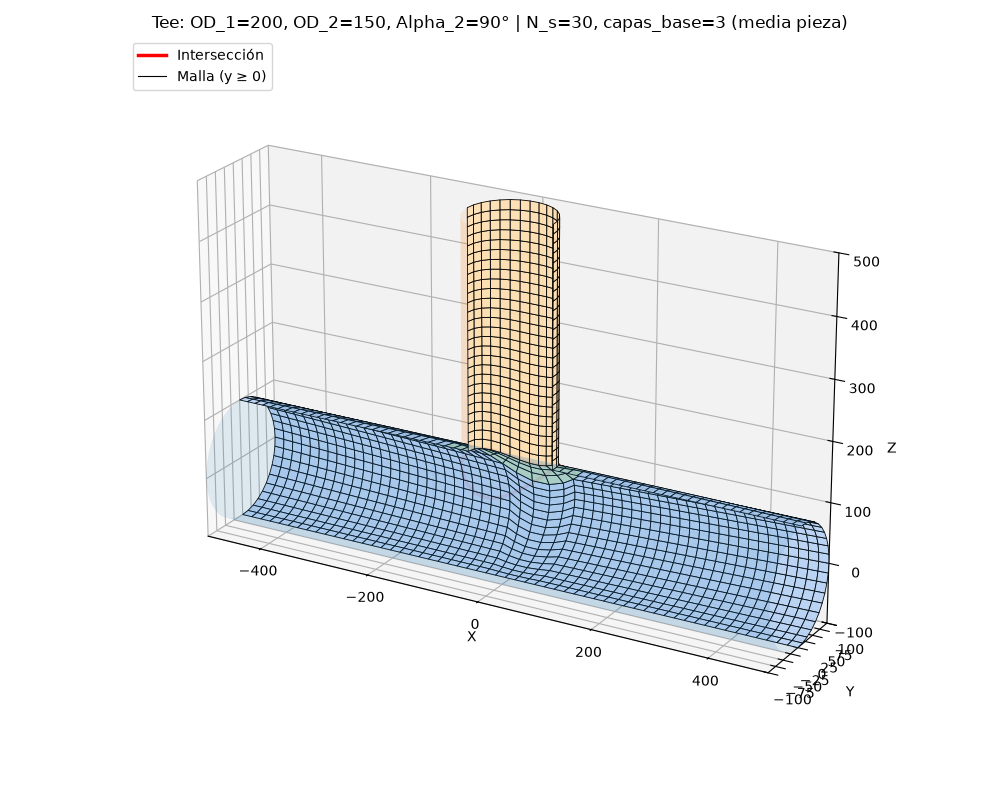

In [89]:
eje_x = np.array([1.0, 0.0, 0.0])

# 1) derivación (media pieza), desde la curva de intersección hasta la boca
nodos_d, quads_d, grupos_d, info = malla_derivacion_mitad(R1, R2, alfa, H_2, N_s, razon, angulo=ANGULO_VERTICE)

# 2) capas de elementos sobre el caño base, en el borde de la curva
nodos_b, quads_b, grupos_b = malla_base_borde_mitad(R1, nodos_d[grupos_d['curva']], capas_base, razon_base, angulo=ANGULO_VERTICE, rel=rel_capa)

# 3) unión (los nodos de la curva se comparten)
nodos, quads, grupo, mapa = unir_mallas(nodos_d, quads_d, nodos_b, quads_b, grupos_d['curva'], grupos_b['curva'])
borde_orden = mapa[grupos_b['borde_orden']]

# 4) completar el caño directo desde las bocas hacia la corona (las bocas tienen que quedar fuera de la corona)
x_borde = nodos[borde_orden, 0]
H_1_min, H_3_min = np.ceil(-x_borde.min() + 2 * tam), np.ceil(x_borde.max() + 2 * tam)
if H_1 < H_1_min or H_3 < H_3_min:
    print(f"AVISO: la corona llega a x = {x_borde.min():.1f} ... {x_borde.max():.1f}; se amplía H_1 {H_1:g} -> {max(H_1, H_1_min):g} y H_3 {H_3:g} -> {max(H_3, H_3_min):g}")
    H_1, H_3 = max(H_1, H_1_min), max(H_3, H_3_min)
nodos, quads, grupo_directo, info_d = completar_base_mitad(R1, nodos, quads, borde_orden, H_1, H_3, N_directo)
grupo = np.concatenate([grupo, grupo_directo])                     # 0 = derivación, 1 = corona, 2 = resto del directo

# 5) (opcional) uniformizar el tamaño quitando elementos donde la malla está comprimida: actúa en toda la derivación y el directo,
#    por eso queda desactivado; la corrección de malla se aplica solo en la zona de las puntas de la corona (paso 6)
UNIFORMIZAR_TAMANO = False
n_antes = len(quads)
if UNIFORMIZAR_TAMANO:
    nodos, quads, grupo, mapa_u = uniformizar_tamano(nodos, quads, grupo, R1, R2, eje_s, perp_s, tam, tam_s)
    print(f"Uniformización de tamaño: {n_antes} -> {len(quads)} elementos")
else:
    mapa_u = np.arange(len(nodos))

# 6) fila delgada pegada a la línea de simetría en los dos extremos de la corona (medio rombo en cada punta)
nodos, quads, grupo, tris_sim, n_nuevos, mapa_s = cuna_simetria(nodos, quads, grupo, R1, tam)
mapa_u = np.where(mapa_u >= 0, mapa_s[np.maximum(mapa_u, 0)], -1)           # los nodos que desaparecen valen -1
print(f"Cuña en la línea de simetría: {n_nuevos} nodos nuevos, {len(tris_sim)} triángulos (se completan como rombos al espejar)")

# 7) enderezar las líneas del directo y llevar los elementos hacia la forma cuadrada (no se mueven los nodos de la cuña)
nodos = alinear_malla(nodos, quads, grupo, R1, fijos=np.arange(len(nodos) - n_nuevos, len(nodos)))
def _remap(a):
    a = mapa_u[np.asarray(a)]
    return np.unique(a[a >= 0])

grupos = {
    'curva':     _remap(grupos_d['curva']),
    'boca':      _remap(grupos_d['boca']),
    'borde_base': _remap(mapa[grupos_b['borde']]),
    'simetria':  _remap(np.concatenate([grupos_d['simetria'], mapa[grupos_b['simetria']]])),
}

print(f"Media pieza: {len(nodos)} nodos, {len(quads)} elementos "
      f"({(grupo == 0).sum()} derivación + {(grupo == 1).sum()} corona + {(grupo == 2).sum()} resto del directo) | M = {info['M']} capas en la derivación")
print(f"Vértices de la curva (índice de nodo): {info['idx_vert'].tolist()}")
print(f"Directo: n = {info_d['n']} filas por bloque lateral, {info_d['filas_inferior']} en el inferior")
print("Control:", control_malla(nodos, quads, grupo, {0: eje_s, 1: eje_x, 2: eje_x}))

graficar(nodos, quads, grupo)

## 11. (Opcional) Espejar y ver la pieza completa

Ejemplo con un campo nodal de prueba: columna 0 = escalar, columnas 1–3 = vector (x, y, z); la componente Y es la columna 2.

Pieza completa: 3154 nodos, 3100 elementos
Control: {'forma_media': 0.96, 'forma_min': 0.619, 'libres': 110, 'mas_de_2': 0, 'orientacion_inconsistente': 0, 'normales_invertidas': 0}


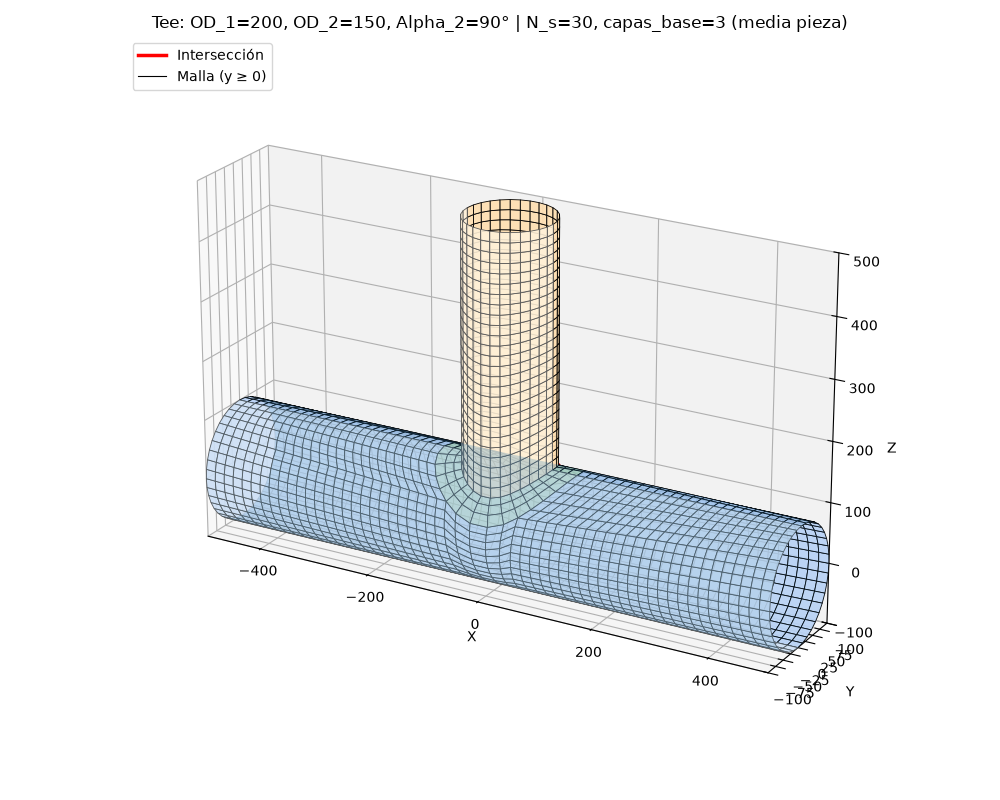

In [90]:
valores = np.column_stack([nodos[:, 2], nodos[:, 0], nodos[:, 1], nodos[:, 2]])

nodos_tot, quads_tot, valores_tot, mapa_esp = espejar_malla(nodos, quads, valores, cols_y=(2,))
grupo_tot = np.concatenate([grupo, grupo[quads[:, 2] != quads[:, 3]]])      # los triángulos no se duplican (forman un rombo con su espejo)
print(f"Pieza completa: {len(nodos_tot)} nodos, {len(quads_tot)} elementos")
print("Control:", control_malla(nodos_tot, quads_tot, grupo_tot, {0: eje_s, 1: eje_x, 2: eje_x}))

import inspect
try:
    _viejo = 'quads_esp[:n_half]' not in inspect.getsource(graficar)
except Exception:
    _viejo = False
if _viejo:
    print("AVISO: el kernel tiene una versión vieja de graficar y el dibujo va a mostrar un hueco donde están los rombos "
          "de la línea de simetría (la malla está bien). Cerrá el notebook sin guardar, reabrilo y reiniciá el kernel.")

graficar(nodos, quads, grupo, mostrar_espejo=True, nodos_esp=nodos_tot, quads_esp=quads_tot)